# MEMAR comparison between miCLIP and GLORI-seq in HEK239T cell line

In [1]:
#Packages needed for the notebook
using CSV 
using Serialization 
using Revise 
using LinearAlgebra 
using ReverseDiff 
using Random 
using PyPlot 
using NaNStatistics
using Statistics 

### Including Files

In [2]:
function correct_path(splitted_path, String)
    """Function to retrieve files in a given path.
    It takes as input:
        1) splitted path: the current path split by each separator
        2) String: the path to reach the wanted file 
    The function returns:
        1) the correct complete path to reach the file
    """
    S="" #String initialization
    for i in 1:(length(splitted_path)-1)
        #Constructing the path with the correct separator and removing the last term
        S=S*splitted_path[i]*"/" 
    end
    #Final Output
    return S*String 
end

correct_path (generic function with 1 method)

In [3]:
#Including files with the functions
includet(correct_path(split(pwd(), '/'), "Functions/Variables and Structures.jl")) #For constant quantities or structures to save data
includet(correct_path(split(pwd(), '/'), "Functions/Inference.jl")) #For Training
includet(correct_path(split(pwd(), '/'), "Functions/Model Strategies and Testing.jl")) #For scoring testing datasets
includet(correct_path(split(pwd(), '/'), "Functions/Performance Indicator.jl")) #To compute performance over test datasets

### Datasets

In [4]:
"""GLORI-seq"""
#Importing constrcutred dataset
train=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Train_GLORI.bin")) 
test=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HEK_CC_GLORI.bin")) 
prior_HEK=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Prior_GLORI.bin")); 
#Saving all the gene labels for the three datasets
gene_train=keys(train);
gene_test=keys(test);
gene_prior=keys(prior_HEK);
#All non methylated As
train_met, ratio_train, gene_train_met, train_not, gene_train_not=crete_set_all(train, gene_train);

In [5]:
"""miCLIP"""
#Importing constrcutred dataset
train_CLIP=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Train_miCLIP.bin")) 
test_CLIP=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Test_miCLIP.bin")) ;
prior_CLIP=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Prior_miCLIP.bin")) 
#Saving all the gene labels for the three datasets
gene_train_CLIP=keys(train_CLIP);
gene_test_CLIP=keys(test_CLIP);
gene_prior_CLIP=keys(prior_CLIP);
#All non methylated As
train_met_CLIP, gene_train_met_CLIP, train_not_CLIP, gene_train_not_CLIP=crete_set_all(train_CLIP, gene_train_CLIP; verbose=false);

### Trained models

In [6]:
"""GLORI"""
#Importing models trained on GLORI HEK293T
M5=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Model_met.bin")) # p(s̄|m)
M6=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Model_not_met.bin")); # p(s̄|m̄)

In [7]:
"""miCLIP"""
#Importing models trained on miCLIP HEK293T
C5=deserialize(correct_path(split(pwd(), '/'),"Mapping/Data/Model_met_CLIP.bin")) # p(s̄|m)
C6=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Model_not_met_CLIP.bin")); # p(s̄|m̄)

### Distibution of motives (train-set):

In [8]:
"""GLORI-seq"""
#Computing distribution of m6A and A over transcripts
bin=collect(0:0.001:1);
avarege_window=20
x_met, y_met=avarege_distribution(train, gene_train, avarege_window, bin; label=1)  # d(x(s̄_T)|m)
x_not, y_not=avarege_distribution(train, gene_train, avarege_window, bin, label=0); # d(x(s̄_T)|m̄)

"""miCLIP""" 
x_met_CLIP, y_met_CLIP=avarege_distribution(train_CLIP, gene_train_CLIP, avarege_window, bin; label=1) # d(x(s̄_T)|m
x_not_CLIP, y_not_CLIP=avarege_distribution(train_CLIP, gene_train_CLIP, avarege_window, bin; label=0); # d(x(s̄_T)|m̄)

### Distribution of methylated sites in metagen profile

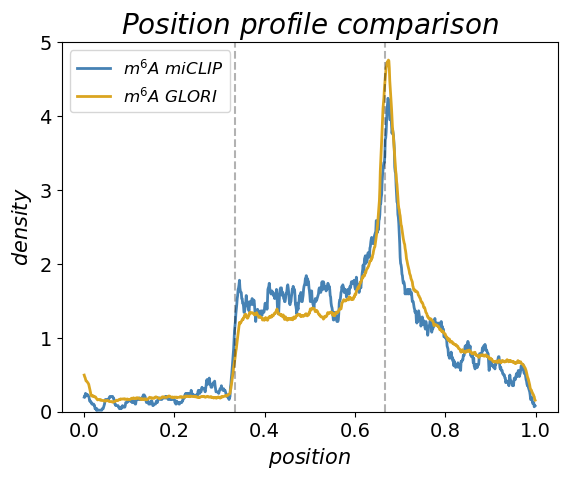

In [9]:
close("all")
plot(x_met_CLIP, y_met_CLIP, color="steelblue", label=L"m^6A \ miCLIP", lw=2)
plot(x_met, y_met, color="goldenrod", label=L"m^6A \ GLORI",lw=2)

ylim(0, 5)
title(L"Position \ profile  \ comparison", size=20)
xlabel(L"position", size=15)
ylabel(L"density", size=15)
axvline(alpha=0.3, c="black", ls="--", x=1/3)
axvline(alpha=0.3, c="black", ls="--", x=2/3)
xticks(fontsize=14)
yticks(fontsize=14)
legend(fontsize=12)
gcf()

### Distribution of non-methylated sites in metagen profile

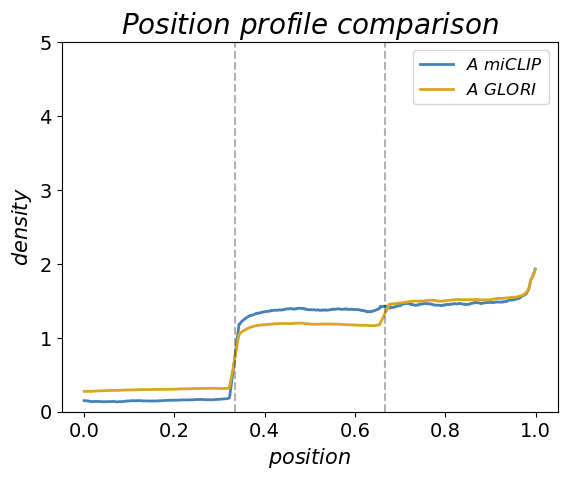

In [10]:
close("all")
plot(x_not_CLIP, y_not_CLIP, color="steelblue", label=L"A \ miCLIP", lw=2)
plot(x_not, y_not, color="goldenrod", label=L"A \ GLORI",lw=2 )
ylim(0, 5)
title(L"Position \ profile  \ comparison", size=20)
xlabel(L"position", size=15)
ylabel(L"density", size=15)
axvline(alpha=0.3, c="black", ls="--", x=1/3)
axvline(alpha=0.3, c="black", ls="--", x=2/3)
xticks(fontsize=14)
yticks(fontsize=14)
legend(fontsize=12)
gcf()


### Distribution of m6A percentage in transcripts

In [11]:
#Saving the percentage of methylated A for each gene in each dataset
dist_1, dist_2=[],[]
[push!(dist_1, train[a].perc_met) for a in keys(train)];
[push!(dist_2, train_CLIP[a].perc_met) for a in keys(train_CLIP)];

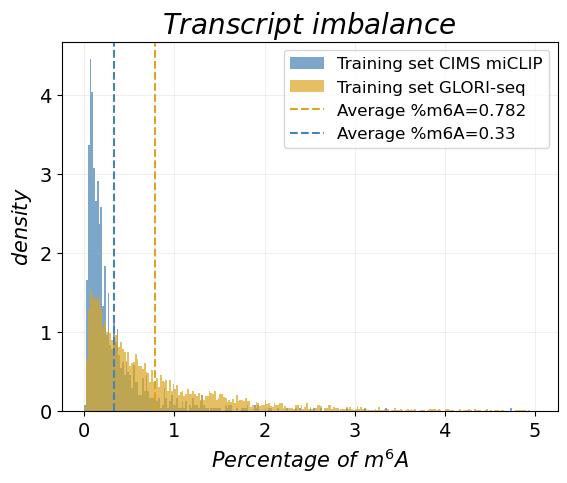

In [12]:
close("all")
BIN=vcat(0:0.02:5)
hist(dist_2, bins=BIN, density=true, color="steelblue", alpha=0.7, label="Training set CIMS miCLIP")
hist(dist_1, bins=BIN, density=true, color="goldenrod",alpha=0.7, label="Training set GLORI-seq")
axvline(x=mean(dist_1), linestyle="--", color="goldenrod", label="Average %m6A=$(round(mean(dist_1), digits=3))")
axvline(x=mean(dist_2), linestyle="--", color="steelblue",label="Average %m6A=$(round(mean(dist_2), digits=3))")
ylabel(L"density", size=15)
grid(alpha=0.2)
xlabel(L"Percentage \ of  \ m^6A", size=15)
xticks(fontsize=14)
yticks(fontsize=14)
legend(fontsize=12)
title(L"Transcript \ imbalance ", size=20)
gcf()

In [13]:
#Filtering over all DRACH motifs training dataset
train_met_D,_=filter_DRACH(train_met; verbose=true, ratio=vcat(ones(1, length(train_met))...)) #GLORI
train_met_D_C,_=filter_DRACH(train_met_CLIP; verbose=true, ratio=vcat(ones(1, length(train_met_CLIP))...)); #miCLIP
mers_5A=[i[1:2]*i[3:4] for i in mots_list4];

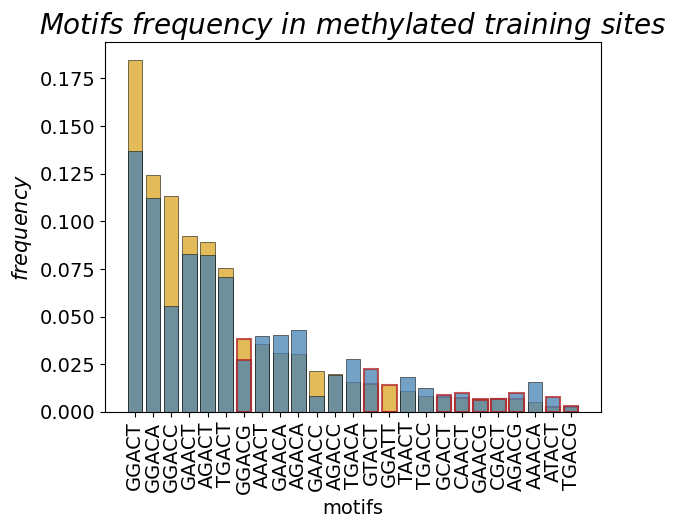

In [14]:
N=25 #Selecting the number of motifs to be shown

close("all")
"""GLORI-seq"""
#Empty dictionary to containg freqeuncies
Dict_5Amers=Dict()
[  Dict_5Amers[a]=0 for a in mers_5A]
L=length(train_met)
[Dict_5Amers[train_met[i][3:6]]+=1/L  for i in 1:L]
#ordering in decreasing order
ind=sortperm(vcat(values(Dict_5Amers)...), rev=true)
#extracting the frequency based on the decreasing order
freq5A=vcat(values(Dict_5Amers)...)[ind] 
#extracting the motifs based on the decreasing order
#Adding the central A to motifs
mot5A=vcat(keys(Dict_5Amers)...)[ind]
MOT5=[mot5A[i][1:2]*"A"*mot5A[i][3:4] for i in 1:length(mot5A)];
#Plotting the result
[(mot5A[i][1:2]*"A"*mot5A[i][3:4] in DRACH) == true ? bar(i, freq5A[i], edgecolor="black", linewidth=0.5, color="goldenrod", alpha=0.75, label="GLORI") : bar(i, freq5A[i],edgecolor="firebrick", linewidth=1.5, color="goldenrod",alpha=0.75) for i in 1:N]


"""miCLIP"""
#Empty dictionary to containg freqeuncies
Dict_5Amers=Dict()
[Dict_5Amers[a]=0 for a in mers_5A]
L=length(train_met_CLIP)
[Dict_5Amers[train_met_CLIP[i][3:6]]+=1/L for i in 1:L]
#extracting the frequency based on the decreasing order previously computed
freq5A=vcat(values(Dict_5Amers)...)[ind]
#Plotting the result
[(mot5A[i][1:2]*"A"*mot5A[i][3:4] in DRACH) == true ? bar(i, freq5A[i], edgecolor="black", linewidth=0.5, color="steelblue", alpha=0.75, label="CISM-miCLIP") : bar(i, freq5A[i],edgecolor="firebrick", linewidth=1.5, color="steelblue",alpha=0.75,) for i in 1:N ]
#Settings
xticks(vcat(1:N...), MOT5[1:N], rotation=90)
xticks(fontsize=14)
yticks(fontsize=14)
xlabel("motifs", size=14)
title(L"Motifs \ frequency \ in \ methylated \ training \ sites", size=20)
ylabel(L"frequency", size=15)
gcf()

